# Wine Quality Prediction Using Machine Learning
**Course:** Predictive Analytics | **Task:** End-to-End Predictive Model Development (CA3)

**Dataset:** UCI Wine Quality (Cortez et al., 2009) - red and white Portuguese *vinho verde* wines  
**Goal:** Predict the sensory quality score (0-10) of a wine from 11 physicochemical measurements.  
**Type of problem:** Supervised **regression** (quality is an ordered score), evaluated with MAE, MSE, RMSE and R².

This notebook follows the KDD / Predictive Modelling stages:
1. Problem definition & data selection
2. Data understanding (EDA)
3. Data preprocessing
4. Feature selection
5. Model development
6. Hyperparameter tuning
7. Evaluation
8. Interpretation of results
9. Conclusion

## 1. Problem definition and data selection

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_validate, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

sns.set_style("whitegrid")
RANDOM_STATE = 42

In [2]:
red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")
red["wine_type"] = "red"
white["wine_type"] = "white"
df = pd.concat([red, white], ignore_index=True)
print("Red wines  :", red.shape)
print("White wines:", white.shape)
print("Combined   :", df.shape)
df.head()

Red wines  : (1599, 13)
White wines: (4898, 13)
Combined   : (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


## 2. Data understanding

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  wine_type             6497 non-null   str    
dtypes: float64(11), int64(1), str(1)
memory usage: 660.0 KB


In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000


In [5]:
print("Missing values per column:")
print(df.isna().sum().sum(), "missing values in total")
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
0 missing values in total
Duplicate rows: 1177


**Observations:** no missing values. There are duplicate rows (identical measurements and score). Features are on very different scales
(e.g. `total sulfur dioxide` is in the hundreds, `chlorides` is below 1), so scaling will matter for linear and distance/kernel based models.

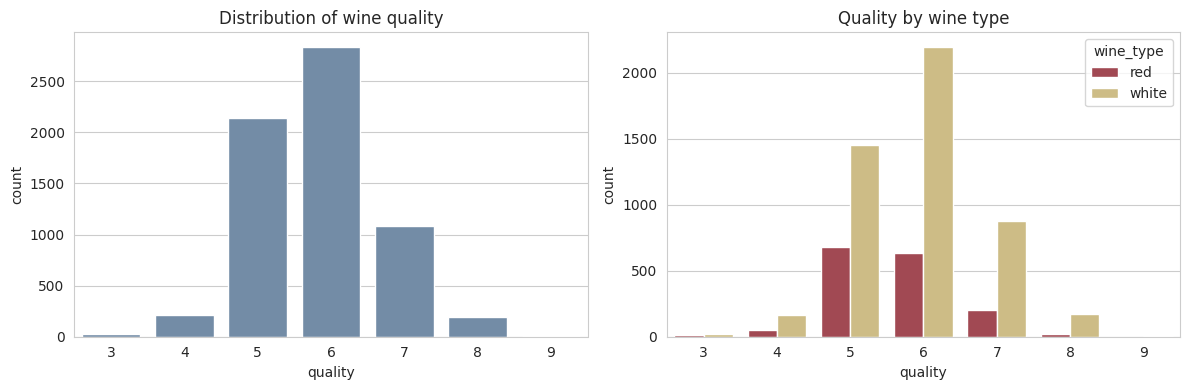

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="quality", data=df, ax=ax[0], color="#6a8caf")
ax[0].set_title("Distribution of wine quality")
sns.countplot(x="quality", hue="wine_type", data=df, ax=ax[1], palette=["#b03a48", "#d9c27a"])
ax[1].set_title("Quality by wine type")
plt.tight_layout(); plt.show()
print(df["quality"].value_counts().sort_index())

Quality is concentrated around 5-6 (about 77% of wines). Scores 3, 4 and 9 are rare, so the target is imbalanced and models will find extreme wines hardest to predict.

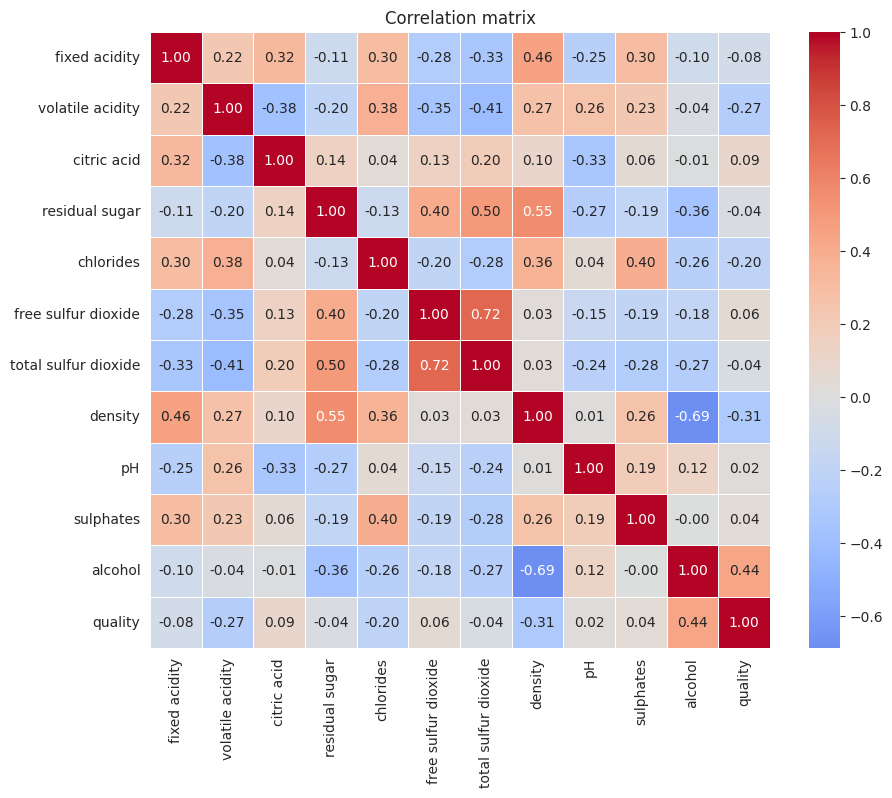

alcohol                 0.444
citric acid             0.086
free sulfur dioxide     0.055
sulphates               0.038
pH                      0.020
residual sugar         -0.037
total sulfur dioxide   -0.041
fixed acidity          -0.077
chlorides              -0.201
volatile acidity       -0.266
density                -0.306
Name: quality, dtype: float64


In [7]:
corr = df.drop(columns="wine_type").corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, linewidths=.5)
plt.title("Correlation matrix"); plt.show()
print(corr["quality"].drop("quality").sort_values(ascending=False).round(3))

`alcohol` has the strongest positive correlation with quality and `density` / `volatile acidity` / `chlorides` are negatively correlated.
`density` is strongly related to `alcohol` and `residual sugar` (multicollinearity), which is worth remembering for linear models.

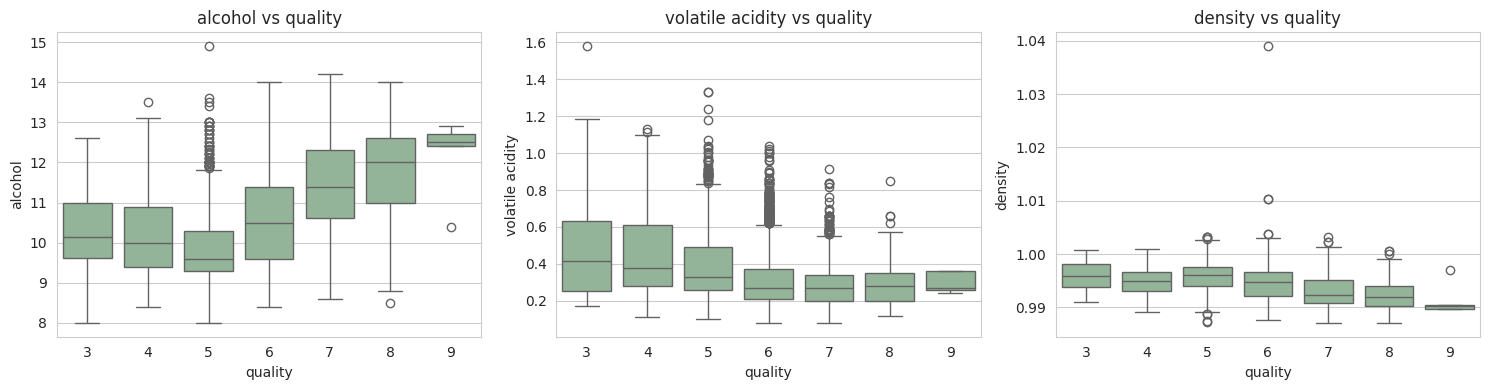

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ["alcohol", "volatile acidity", "density"]):
    sns.boxplot(x="quality", y=col, data=df, ax=a, color="#8fb996")
    a.set_title(f"{col} vs quality")
plt.tight_layout(); plt.show()

## 3. Data preprocessing

Steps and reasons:
1. **Remove duplicate rows** - identical rows can land in both train and test sets and inflate scores (data leakage).
2. **Encode `wine_type`** as a 0/1 column (`is_white`).
3. **Train/test split (80/20)** done *before* outlier handling and scaling, so the test set stays unseen.
4. **Cap extreme outliers** at 3×IQR using limits learned only from the training set.
5. **Standardise features** inside a Pipeline (fitted on training folds only).

In [9]:
before = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
df_clean["is_white"] = (df_clean["wine_type"] == "white").astype(int)
df_clean = df_clean.drop(columns="wine_type")
print(f"Rows before: {before}, after removing duplicates: {len(df_clean)}")

X = df_clean.drop(columns="quality")
y = df_clean["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

Rows before: 6497, after removing duplicates: 5320
Train: (4256, 12)  Test: (1064, 12)


In [10]:
# Cap extreme outliers (3 x IQR) using limits learned on TRAIN only
cont_cols = [c for c in X.columns if c != "is_white"]
q1, q3 = X_train[cont_cols].quantile(0.25), X_train[cont_cols].quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 3 * iqr, q3 + 3 * iqr

n_capped = ((X_train[cont_cols] < lower) | (X_train[cont_cols] > upper)).sum().sum()
print("Train values capped:", int(n_capped))

X_train_c = X_train.copy(); X_test_c = X_test.copy()
X_train_c[cont_cols] = X_train[cont_cols].clip(lower, upper, axis=1)
X_test_c[cont_cols]  = X_test[cont_cols].clip(lower, upper, axis=1)

Train values capped: 226


## 4. Feature selection

The dataset page notes that not all inputs may be relevant, so we check feature relevance with a quick Random Forest importance score
and with mutual information, instead of assuming every feature is useful.

,RF_importance,Mutual_info
alcohol,0.2585,0.1443
volatile acidity,0.1151,0.0452
free sulfur dioxide,0.0929,0.0105
sulphates,0.0787,0.0301
total sulfur dioxide,0.0778,0.0480
pH,0.0726,0.0178
residual sugar,0.0668,0.0192
chlorides,0.0649,0.0559
citric acid,0.0585,0.0348
fixed acidity,0.0575,0.0169


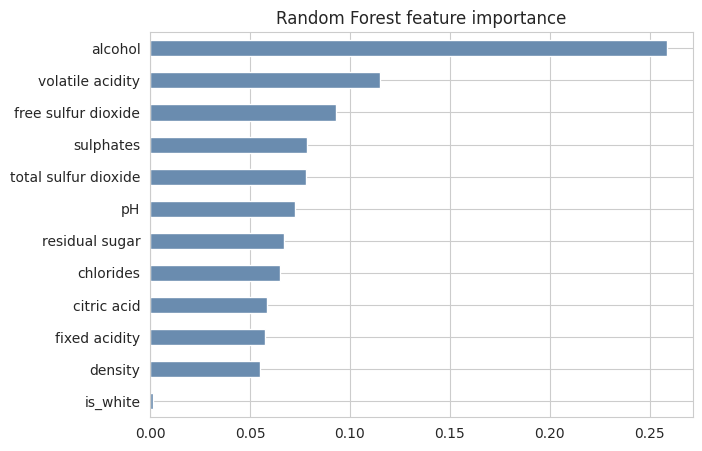

In [11]:
from sklearn.feature_selection import mutual_info_regression
rf_fs = RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1).fit(X_train_c, y_train)
fs = pd.DataFrame({
    "RF_importance": rf_fs.feature_importances_,
    "Mutual_info": mutual_info_regression(X_train_c, y_train, random_state=RANDOM_STATE)
}, index=X_train_c.columns).sort_values("RF_importance", ascending=False)
display(fs.round(4))
fs["RF_importance"].sort_values().plot.barh(figsize=(7, 5), color="#6a8caf")
plt.title("Random Forest feature importance"); plt.show()

Most features carry useful signal. `is_white` scores very low on Random Forest importance (and only moderate on mutual information), because the red/white difference is largely already captured by the sulfur dioxide and acidity features.
It is harmless to keep, so we **keep all 12 features** and let the models decide. Removing weak features did not look necessary for tree ensembles.

## 5. Model development

**Evaluation metrics (regression):**
- **MAE** = average absolute difference between predicted and actual score (in quality points). Easy to interpret.
- **MSE** = average squared error. Penalises large mistakes more.
- **RMSE** = √MSE, back in quality points.
- **R²** = fraction of the variance in quality that the model explains (1 is perfect, 0 is no better than predicting the mean).

A **Dummy model** (always predicts the mean quality) is used as a baseline. Every real model must beat it.
Models are compared using **5-fold cross-validation on the training set**, then scored once on the test set.

In [12]:
models = {
    "Dummy (mean)":       DummyRegressor(strategy="mean"),
    "Linear Regression":  LinearRegression(),
    "Ridge Regression":   Ridge(alpha=1.0),
    "Decision Tree":      DecisionTreeRegressor(max_depth=6, random_state=RANDOM_STATE),
    "SVR (RBF)":          SVR(C=3.0),
    "Random Forest":      RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting":  GradientBoostingRegressor(random_state=RANDOM_STATE),
    "XGBoost":            XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=5,
                                       random_state=RANDOM_STATE, n_jobs=-1),
}
pipes = {n: Pipeline([("scaler", StandardScaler()), ("model", m)]) for n, m in models.items()}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"mae": "neg_mean_absolute_error", "mse": "neg_mean_squared_error", "r2": "r2"}

rows = []
for name, pipe in pipes.items():
    cv = cross_validate(pipe, X_train_c, y_train, cv=kf, scoring=scoring, n_jobs=-1)
    pipe.fit(X_train_c, y_train)
    pred = pipe.predict(X_test_c)
    rows.append({
        "Model": name,
        "CV MAE": -cv["test_mae"].mean(),
        "CV R2": cv["test_r2"].mean(),
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test MSE": mean_squared_error(y_test, pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test R2": r2_score(y_test, pred),
    })
results = pd.DataFrame(rows).sort_values("Test R2", ascending=False).reset_index(drop=True)
results.round(4)

,Model,CV MAE,CV R2,Test MAE,Test MSE,Test RMSE,Test R2
0,Random Forest,0.5324,0.3762,0.5310,0.4722,0.6872,0.3904
1,XGBoost,0.5434,0.3562,0.5286,0.4758,0.6898,0.3857
2,Gradient Boosting,0.5472,0.3537,0.5375,0.4812,0.6937,0.3788
3,SVR (RBF),0.5342,0.3607,0.5389,0.5056,0.7110,0.3473
4,Linear Regression,0.5635,0.3101,0.5652,0.5322,0.7295,0.3129
5,Ridge Regression,0.5635,0.3101,0.5652,0.5322,0.7295,0.3129
6,Decision Tree,0.5856,0.2308,0.5693,0.5641,0.7511,0.2717
7,Dummy (mean),0.6949,-0.0016,0.6948,0.7746,0.8801,-0.0000


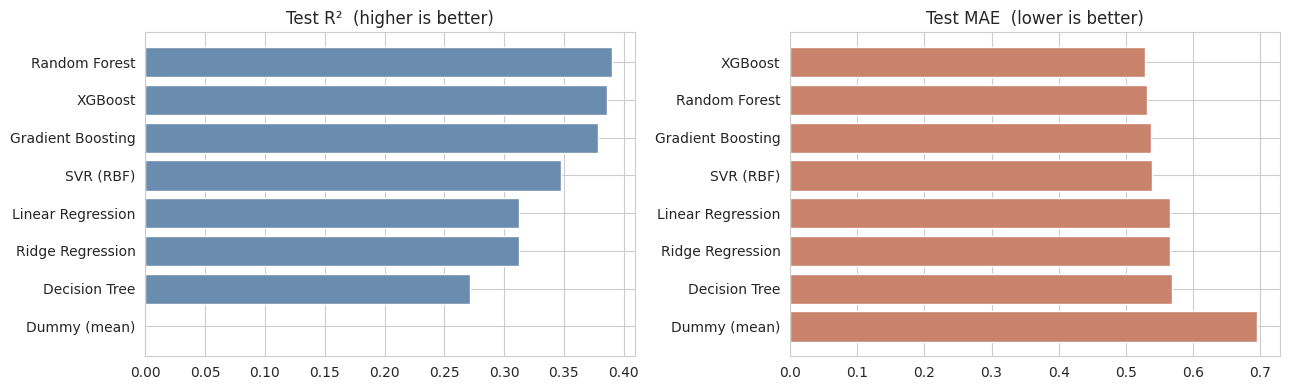

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
order = results.sort_values("Test R2")
ax[0].barh(order["Model"], order["Test R2"], color="#6a8caf"); ax[0].set_title("Test R²  (higher is better)")
order = results.sort_values("Test MAE", ascending=False)
ax[1].barh(order["Model"], order["Test MAE"], color="#c9826b"); ax[1].set_title("Test MAE  (lower is better)")
plt.tight_layout(); plt.show()

## 6. Hyperparameter tuning

The two strongest model families (Random Forest and XGBoost) are tuned with `RandomizedSearchCV` (5-fold CV, optimising R²) on the training data only.

In [14]:
rf_space = {
    "model__n_estimators": [200, 300, 400],
    "model__max_depth": [None, 15, 25],
    "model__min_samples_leaf": [1, 2, 3],
    "model__max_features": ["sqrt", 0.5, 0.8],
}
xgb_space = {
    "model__n_estimators": [200, 300, 400],
    "model__learning_rate": [0.02, 0.05, 0.1],
    "model__max_depth": [4, 6, 8],
    "model__subsample": [0.7, 0.85, 1.0],
    "model__colsample_bytree": [0.7, 0.85, 1.0],
    "model__min_child_weight": [1, 3, 5],
}
searches = {}
for name, base, space in [
    ("Random Forest (tuned)", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), rf_space),
    ("XGBoost (tuned)", XGBRegressor(random_state=RANDOM_STATE, n_jobs=-1), xgb_space),
]:
    pipe = Pipeline([("scaler", StandardScaler()), ("model", base)])
    s = RandomizedSearchCV(pipe, space, n_iter=8, cv=kf, scoring="r2",
                           random_state=RANDOM_STATE, n_jobs=1)
    s.fit(X_train_c, y_train)
    searches[name] = s
    print(f"{name}: best CV R² = {s.best_score_:.4f}")
    print("   best params:", {k.replace('model__',''): v for k, v in s.best_params_.items()})

Random Forest (tuned): best CV R² = 0.3862
   best params: {'n_estimators': 200, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': None}


XGBoost (tuned): best CV R² = 0.3882
   best params: {'subsample': 0.7, 'n_estimators': 200, 'min_child_weight': 5, 'max_depth': 8, 'learning_rate': 0.02, 'colsample_bytree': 0.7}


## 7. Final evaluation on the unseen test set

In [15]:
final_rows = []
for name, s in searches.items():
    pred = s.best_estimator_.predict(X_test_c)
    final_rows.append({
        "Model": name,
        "CV R2": s.best_score_,
        "Test MAE": mean_absolute_error(y_test, pred),
        "Test MSE": mean_squared_error(y_test, pred),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "Test R2": r2_score(y_test, pred),
    })
final = pd.DataFrame(final_rows).sort_values("Test R2", ascending=False).reset_index(drop=True)
display(final.round(4))

best_name = final.iloc[0]["Model"]
best_model = searches[best_name].best_estimator_
y_pred = best_model.predict(X_test_c)
print("Selected final model:", best_name)

,Model,CV R2,Test MAE,Test MSE,Test RMSE,Test R2
0,XGBoost (tuned),0.3882,0.5243,0.4596,0.6780,0.4066
1,Random Forest (tuned),0.3862,0.5241,0.4612,0.6791,0.4046


Selected final model: XGBoost (tuned)


In [16]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

y_round = np.clip(np.rint(y_pred), 3, 9)
acc_exact = (y_round == y_test).mean()
acc_pm1 = (np.abs(y_round - y_test) <= 1).mean()

print(f"MAE  : {mae:.4f}   (average error in quality points)")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R²   : {r2:.4f}   ({r2*100:.1f}% of the variance in quality explained)")
print(f"Accuracy after rounding prediction to nearest score : {acc_exact*100:.1f}%")
print(f"Prediction within ±1 quality point                  : {acc_pm1*100:.1f}%")

MAE  : 0.5243   (average error in quality points)
MSE  : 0.4596
RMSE : 0.6780
R²   : 0.4066   (40.7% of the variance in quality explained)
Accuracy after rounding prediction to nearest score : 55.6%
Prediction within ±1 quality point                  : 97.3%


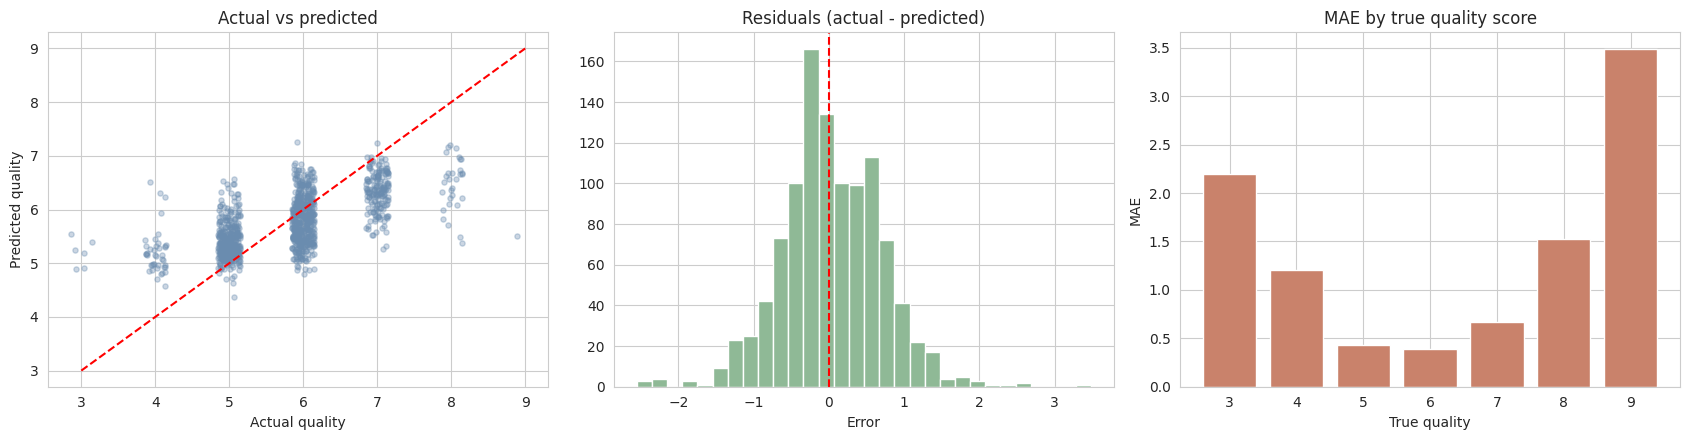

actual
3    2.197
4    1.209
5    0.431
6    0.388
7    0.669
8    1.527
9    3.486
Name: abs_err, dtype: float64


In [17]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

jitter = np.random.RandomState(0).uniform(-0.15, 0.15, len(y_test))
ax[0].scatter(y_test + jitter, y_pred, alpha=0.35, s=14, color="#6a8caf")
ax[0].plot([3, 9], [3, 9], "r--", lw=1.5)
ax[0].set_xlabel("Actual quality"); ax[0].set_ylabel("Predicted quality"); ax[0].set_title("Actual vs predicted")

resid = y_test - y_pred
ax[1].hist(resid, bins=30, color="#8fb996", edgecolor="white")
ax[1].axvline(0, color="r", ls="--"); ax[1].set_title("Residuals (actual - predicted)")
ax[1].set_xlabel("Error")

per_class = pd.DataFrame({"actual": y_test.values, "abs_err": np.abs(resid.values)}).groupby("actual")["abs_err"].mean()
ax[2].bar(per_class.index.astype(str), per_class.values, color="#c9826b")
ax[2].set_title("MAE by true quality score"); ax[2].set_xlabel("True quality"); ax[2].set_ylabel("MAE")
plt.tight_layout(); plt.show()
print(per_class.round(3))

**Reading the plots:** points close to the red dashed line mean accurate predictions. The model tends to **pull extreme wines toward the middle** (high quality is under-predicted, low quality over-predicted),
which is visible in the third chart where the error is largest for the rare scores 3, 8 and 9. This is the typical effect of an imbalanced target.

## 8. Interpretation of results

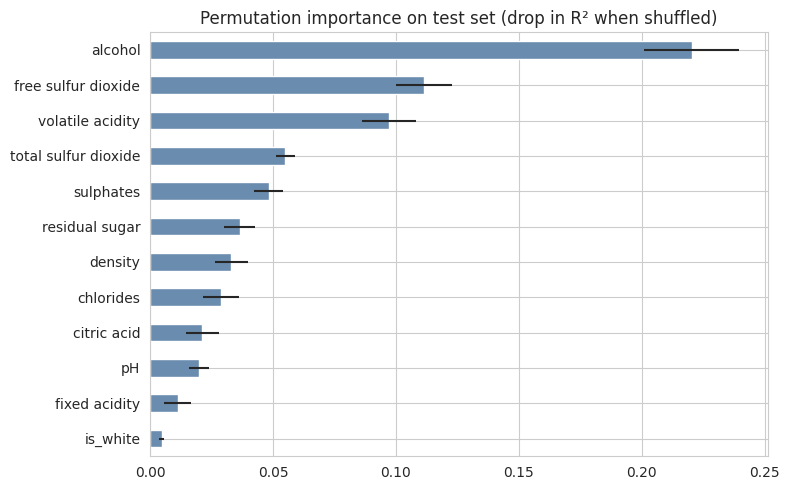

alcohol                 0.2203
free sulfur dioxide     0.1115
volatile acidity        0.0971
total sulfur dioxide    0.0551
sulphates               0.0482
residual sugar          0.0364
density                 0.0331
chlorides               0.0289
citric acid             0.0212
pH                      0.0199
fixed acidity           0.0112
is_white                0.0047
dtype: float64


In [18]:
perm = permutation_importance(best_model, X_test_c, y_test, n_repeats=15,
                              random_state=RANDOM_STATE, scoring="r2", n_jobs=1)
imp = pd.Series(perm.importances_mean, index=X_test_c.columns).sort_values()
imp.plot.barh(figsize=(8, 5), xerr=pd.Series(perm.importances_std, index=X_test_c.columns)[imp.index],
              color="#6a8caf")
plt.title("Permutation importance on test set (drop in R² when shuffled)")
plt.tight_layout(); plt.show()
print(imp.sort_values(ascending=False).round(4))

- **Alcohol** is by far the most influential feature: wines with higher alcohol tend to receive higher scores.
- **Free sulfur dioxide** and **volatile acidity** (vinegar-like taste, which lowers quality) come next.
- Total sulfur dioxide, sulphates, residual sugar, density and chlorides contribute smaller but real signal; `is_white` and `fixed acidity` matter least.

## 9. Summary and conclusion

In [19]:
base = results.loc[results["Model"] == "Dummy (mean)"].iloc[0]
lin = results.loc[results["Model"] == "Linear Regression"].iloc[0]
print(f"Baseline (always predict mean) : MAE = {base['Test MAE']:.3f}, R² = {base['Test R2']:.3f}")
print(f"Linear Regression              : MAE = {lin['Test MAE']:.3f}, R² = {lin['Test R2']:.3f}")
print(f"Final model ({best_name:<22}): MAE = {mae:.3f}, MSE = {mse:.3f}, RMSE = {rmse:.3f}, R² = {r2:.3f}")
print(f"Improvement in MAE over baseline: {(1 - mae/base['Test MAE'])*100:.1f}%")

Baseline (always predict mean) : MAE = 0.695, R² = -0.000
Linear Regression              : MAE = 0.565, R² = 0.313
Final model (XGBoost (tuned)       ): MAE = 0.524, MSE = 0.460, RMSE = 0.678, R² = 0.407
Improvement in MAE over baseline: 24.5%


**Conclusion**
- Wine quality can be predicted from physicochemical properties with moderate accuracy: the tuned ensemble model cuts the error (MAE) by roughly a quarter compared with the mean baseline and does better than linear regression, but it explains only about 40% of the variance in quality.
- Non-linear ensemble models (Random Forest / XGBoost) work better than linear models, which suggests the relationship between chemistry and quality is non-linear. Random Forest and XGBoost ended up almost identical.
- A large share of the variance remains unexplained because quality is a subjective sensory score that also depends on factors not in the data (grape type, brand, taste of the tasters).

**Limitations and future work**
- The target is imbalanced, so extreme wines are predicted poorly; techniques such as class weighting, SMOTE or ordinal classification could be tested.
- Only vinho verde wines from one region are included, so conclusions may not generalise to other wines.
- Next steps: SHAP explanations, LightGBM/CatBoost, and treating the problem as ordinal classification.

**Reference:** P. Cortez, A. Cerdeira, F. Almeida, T. Matos, J. Reis (2009). *Modeling wine preferences by data mining from physicochemical properties.* Decision Support Systems. Dataset DOI: 10.24432/C56S3T.